# **Group4-day2-assignment**
## Predicting the Energy Rating (EPC band) from Gas and Electricity Consumption – Model Training

## 1. Objective

The objective is to train a machine-learning model that answers the question:

> *"If this is the gas and electricity consumption of a home, what is its energy rating?"*

We predict the **EPC band** (Energy Performance Certificate rating) of residential properties from their annual **gas** and **electricity** consumption, helped by basic building characteristics and insulation measures.

**Target variable:** `EPC`

| EPC band | Meaning |
|---|---|
| A/B | very efficient |
| C | efficient |
| D | average |
| E | inefficient |
| F/G | very inefficient |

Homes marked `No EPC` have no certificate, so we can't learn from them. We set them aside and estimate their rating with the finished model at the end (section 6.4).

**Input features:**

* Fuel consumption: annual gas (`Gcons2024`) and electricity (`Econs2024`) consumption in kWh.
* Building characteristics: floor area band, property type, age band and region.
* Energy-efficiency measures: loft insulation (`LI_FLAG`), cavity wall insulation (`CWI_FLAG`) and solar panels (`PV_FLAG`).

Because the target is a **band** (a category), this is a **classification** problem.

## 2. Modelling Workflow

1. Load the prepared dataset and explore how fuel consumption changes with the EPC band.
2. Define the input features and target, and remove homes without an EPC.
3. Split the data into training and test sets (stratified by EPC band).
4. Build a preprocessing pipeline for numerical and categorical features.
5. Establish a baseline model.
6. Train and compare multiple classification models using cross-validation.
7. Test which inputs matter: gas only, gas + electricity, + floor area, + building info, + insulation.
8. Handle the class imbalance and tune the best model.
9. Evaluate the selected model on the test set.
10. Explain the model with permutation importance.
11. Save the final model and use it: *"if fuel use is X, the EPC band is Y"*, and estimate the rating of homes without an EPC.

## 3. Evaluation Metric

We will use the **macro F1-score** as the primary metric. It averages the F1-score of each EPC band **equally**, so the rare bands (A/B and especially F/G) count as much as the common ones. Higher is better (1.0 = perfect).

We also report:

* **Accuracy:** share of homes placed in exactly the right EPC band.
* **Within ±1 band:** share of homes placed in the right band or a neighbouring one (e.g. C instead of D). EPC bands are ordered, so one band off is a much smaller mistake than three bands off.

# 0. Setup
## 0.1 Libraries

In [1]:
# Only needed in a new environment: remove the "#" and run this cell once.
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib   # to save and load trained models

In [3]:
# --- Folders (this notebook lives in notebooks/, so we go up one level with "..") ---
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
MODEL_DIR = Path("../models")   # trained models will be saved here
for folder in [FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings ------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# The same seed everywhere: same splits, same "random" models, same results for everybody
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.2 Dataset: domestic energy consumption (from Day 1)

In [4]:
data_path = DATA_DIR / "anon2026_50k_cleaned.csv"

if not data_path.exists():
    raise FileNotFoundError(
        f"{data_path} not found. Copy anon2026_50k_cleaned.csv into the data/ folder of the repository."
    )

df = pd.read_csv(data_path)
print(f"Homes: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[["EPC", "Gcons2024", "Econs2024", "FLOOR_AREA_BAND", "PROP_TYPE", "PROP_AGE_BAND", "LI_FLAG", "CWI_FLAG"]].head()

Homes: 49,998 rows x 96 columns


,EPC,Gcons2024,Econs2024,FLOOR_AREA_BAND,PROP_TYPE,PROP_AGE_BAND,LI_FLAG,CWI_FLAG
0,C,"6,600.000","3,100.000",2,Semi detached,3,0,0
1,No EPC,"13,500.000","4,200.000",3,Mid terrace,1,0,0
2,A/B,"9,700.000","2,400.000",3,Detached,4,0,0
3,A/B,"5,700.000","3,000.000",2,Semi detached,4,0,0
4,D,"11,500.000","1,700.000",2,Bungalow,2,1,0


In [5]:
# EPC bands from best to worst: we use this order in every table and plot
EPC_ORDER = ["A/B", "C", "D", "E", "F/G"]
EPC_RANK = {band: rank for rank, band in enumerate(EPC_ORDER)}   # A/B -> 0, ..., F/G -> 4

FLOOR_AREA_LABELS = {1: "up to 50 m²", 2: "51-100 m²", 3: "101-150 m²", 4: "151-200 m²", 5: "over 200 m²"}
REGION_NAMES = {
    "E12000001": "North East", "E12000002": "North West", "E12000003": "Yorkshire and The Humber",
    "E12000004": "East Midlands", "E12000005": "West Midlands", "E12000006": "East of England",
    "E12000007": "London", "E12000008": "South East", "E12000009": "South West", "W92000004": "Wales",
}

# 1. Exploring the data
## 1.1 How does fuel consumption change with the EPC band?

In [6]:
gas_homes = df.dropna(subset=["Gcons2024"])   # homes with a 2024 gas reading

epc_summary = gas_homes.groupby("EPC").agg(
    homes=("EPC", "size"),
    median_gas_kWh=("Gcons2024", "median"),
    median_elec_kWh=("Econs2024", "median"),
).reindex(EPC_ORDER + ["No EPC"])
epc_summary["share (%)"] = epc_summary["homes"] / epc_summary["homes"].sum() * 100
epc_summary

,homes,median_gas_kWh,median_elec_kWh,share (%)
EPC,,,,
A/B,3476,"7,200.000","2,300.000",8.800
C,9527,"8,300.000","2,300.000",24.118
D,10983,"10,500.000","2,600.000",27.804
E,2568,"12,200.000","2,800.000",6.501
F/G,312,"12,900.000","2,800.000",0.790
No EPC,12636,"11,400.000","2,500.000",31.988


Figure saved to ..\figures\04_01_fuel_by_epc_band.png


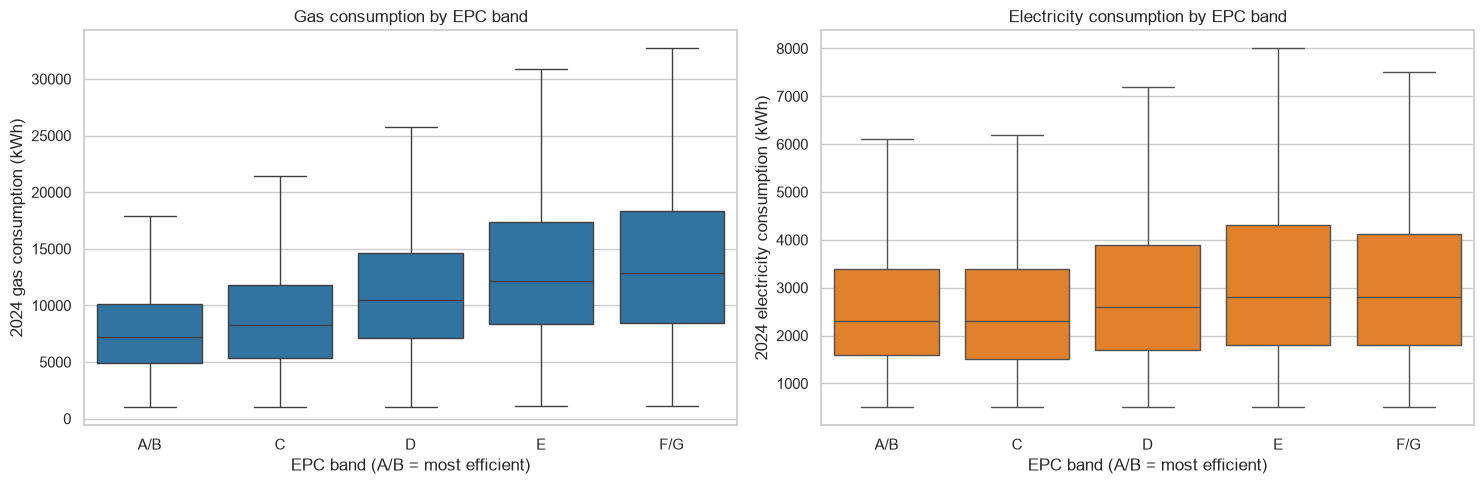

In [7]:
known = gas_homes[gas_homes["EPC"] != "No EPC"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=known, x="EPC", y="Gcons2024", order=EPC_ORDER, showfliers=False, color="tab:blue", ax=axes[0])
axes[0].set_title("Gas consumption by EPC band")
axes[0].set_xlabel("EPC band (A/B = most efficient)")
axes[0].set_ylabel("2024 gas consumption (kWh)")

sns.boxplot(data=known, x="EPC", y="Econs2024", order=EPC_ORDER, showfliers=False, color="tab:orange", ax=axes[1])
axes[1].set_title("Electricity consumption by EPC band")
axes[1].set_xlabel("EPC band (A/B = most efficient)")
axes[1].set_ylabel("2024 electricity consumption (kWh)")

plt.tight_layout()
save_fig("04_01_fuel_by_epc_band")
plt.show()

**Reading the results:** gas consumption rises as the EPC band gets worse: the median goes from **7,200 kWh** for A/B homes to **12,900 kWh** for F/G homes, almost **double**. Electricity changes much less (2,300 → 2,800 kWh), because in these gas-heated homes electricity is used mainly for appliances and lighting, not heating. The boxes **overlap a lot**, and about **32%** of homes have no EPC at all.

## 1.2 The size problem: gas use per floor area band

A big efficient house can use as much gas as a small inefficient one. To see the real effect of efficiency, we compare homes **of the same size**.

Figure saved to ..\figures\04_02_gas_by_size_and_epc.png


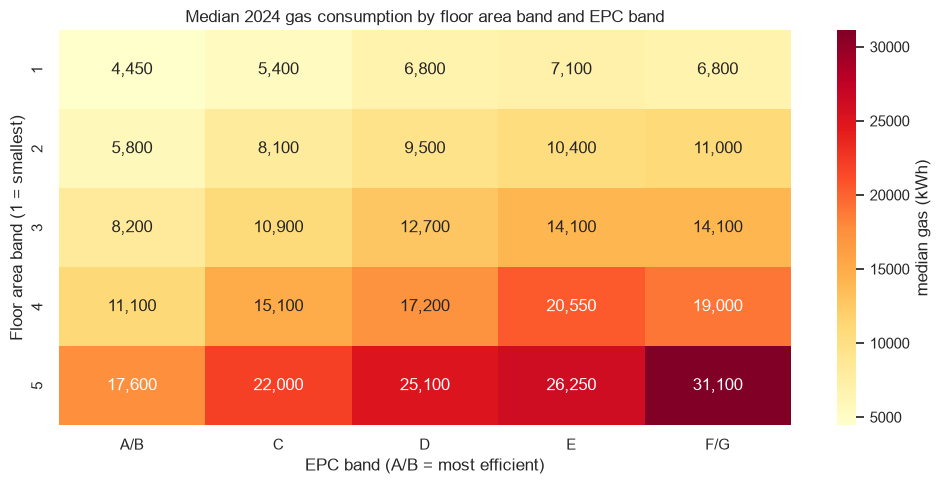

In [8]:
gas_by_size = known.pivot_table(index="FLOOR_AREA_BAND", columns="EPC", values="Gcons2024", aggfunc="median")[EPC_ORDER]

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(gas_by_size, annot=True, fmt=",.0f", cmap="YlOrRd", cbar_kws={"label": "median gas (kWh)"}, ax=ax)
ax.set_title("Median 2024 gas consumption by floor area band and EPC band")
ax.set_xlabel("EPC band (A/B = most efficient)")
ax.set_ylabel("Floor area band (1 = smallest)")
plt.tight_layout()
save_fig("04_02_gas_by_size_and_epc")
plt.show()

**Reading the results:** read the heatmap **row by row**. Within the same floor area band, gas use clearly grows from left (A/B) to right (F/G). In band 2 (51–100 m²) it goes from **5,800** to **11,000 kWh**. But a large efficient home (band 5, A/B: **17,600 kWh**) uses more gas than a small very inefficient one (band 1, F/G: **6,800 kWh**). **Gas consumption only says something about efficiency once we know the size.**

## 1.3 EPC band by property age

Figure saved to ..\figures\04_03_epc_by_age.png


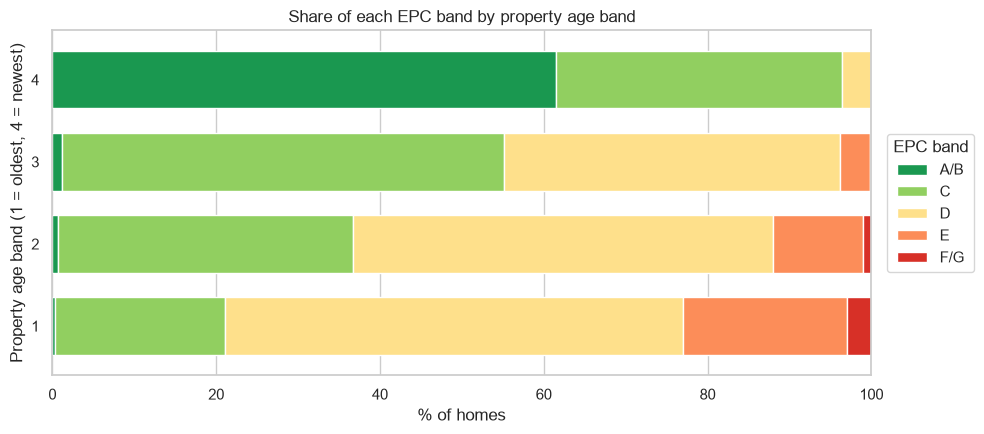

In [9]:
epc_by_age = pd.crosstab(known["PROP_AGE_BAND"], known["EPC"], normalize="index")[EPC_ORDER] * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
epc_by_age.plot.barh(stacked=True, color=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"], width=0.7, ax=ax)
ax.set_title("Share of each EPC band by property age band")
ax.set_xlabel("% of homes")
ax.set_ylabel("Property age band (1 = oldest, 4 = newest)")
ax.set_xlim(0, 100)
ax.legend(title="EPC band", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
save_fig("04_03_epc_by_age")
plt.show()

**Reading the results:** property age is a very strong signal. **58%** of the newest homes (age band 4) are rated A/B, while the oldest homes (age band 1) are mostly D (52%) and E or F/G (27%). Newer homes are built to stricter energy regulations, and the EPC rating is calculated mostly from the building fabric, not from how much energy people actually use.

# 2. Features, target and train/test split
## 2.1 Choosing the features

In [10]:
TARGET = "EPC"

fuel_features = ["Gcons2024", "Econs2024"]                                  # what the question is about
building_numeric = ["FLOOR_AREA_BAND", "PROP_AGE_BAND"]                     # ordered codes: kept as numbers
measure_features = ["LI_FLAG", "CWI_FLAG", "PV_FLAG"]                       # 0/1 flags: kept as numbers
building_nominal = ["PROP_TYPE", "REGION"]                                  # categories without order: one-hot

numeric_features = fuel_features + building_numeric + measure_features
nominal_features = building_nominal

# Only homes with a 2024 gas reading AND a known EPC band
model_df = df.dropna(subset=["Gcons2024"])
no_epc_df = model_df[model_df[TARGET] == "No EPC"].copy()    # kept aside for section 6.4
model_df = model_df[model_df[TARGET] != "No EPC"].copy()

X = model_df[numeric_features + nominal_features]
y = model_df[TARGET]

print(f"Homes with gas reading and EPC: {len(model_df):,}")
print(f"Homes with gas reading but no EPC (set aside): {len(no_epc_df):,}")
print("Numeric:", numeric_features)
print("Nominal:", nominal_features)

Homes with gas reading and EPC: 26,866
Homes with gas reading but no EPC (set aside): 12,636
Numeric: ['Gcons2024', 'Econs2024', 'FLOOR_AREA_BAND', 'PROP_AGE_BAND', 'LI_FLAG', 'CWI_FLAG', 'PV_FLAG']
Nominal: ['PROP_TYPE', 'REGION']


💡 **Note:** `MAIN_HEAT_FUEL` is left out because every home with a gas reading and an EPC has the same value (1 = gas), so it carries no information here. Unlike the floor area notebook, `FLOOR_AREA_BAND` is now a fair **input**: it is not the answer, and we saw in 1.2 that the model needs it to separate "big" from "inefficient".

## 2.2 Train/test split

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,              # 20% for the test set
    stratify=y,                 # keep the same share of each EPC band in train and test
    random_state=RANDOM_STATE,
)

# The stratified 5-fold splitter we will use for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Training set: {len(X_train):,} homes")
print(f"Test set:     {len(X_test):,} homes (locked away until section 4!)")

pd.DataFrame({
    "train (%)": y_train.value_counts(normalize=True).reindex(EPC_ORDER) * 100,
    "test (%)": y_test.value_counts(normalize=True).reindex(EPC_ORDER) * 100,
}).round(1)

Training set: 21,492 homes
Test set:     5,374 homes (locked away until section 4!)


,train (%),test (%)
EPC,,
A/B,12.900,12.900
C,35.500,35.500
D,40.900,40.900
E,9.600,9.600
F/G,1.200,1.200


The classes are **imbalanced**: bands C and D together make up **76%** of the homes, while F/G is only **1.2%** (about 250 homes in the training set). A model that always answers "D" would already be right 41% of the time. That's why we use **macro F1** and not only accuracy.

## 2.3 Preprocessing pipeline

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def make_pipeline_for(model, numeric=numeric_features, nominal=nominal_features, scale=True):
    # Build preprocessing + model as one Pipeline.
    #   model   : any scikit-learn classifier
    #   numeric : numeric columns (missing values -> median, optionally scaled)
    #   nominal : categorical columns (missing values -> most frequent, then one-hot encoded)
    #   scale   : True for linear models / KNN, False for trees
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = [("num", Pipeline(numeric_steps), numeric)]
    if nominal:
        transformers.append(("nom", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), nominal))

    return Pipeline([
        ("preprocess", ColumnTransformer(transformers)),
        ("model", model),
    ])

# 3. Training and comparing models
## 3.1 The model zoo

In [13]:
from sklearn.model_selection import cross_validate


def compare_models(pipelines, X, y, cv, scoring):
    # Cross-validate every pipeline and return one row of results per model.
    #   scoring: dict {display name: scikit-learn scorer name}
    rows = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)  # n_jobs=-1: use all CPU cores
        row = {"model": name}
        for metric in scoring:
            row[f"{metric} mean"] = res[f"test_{metric}"].mean()
            row[f"{metric} std"] = res[f"test_{metric}"].std()
        row["fit time (s)"] = res["fit_time"].mean()
        rows.append(row)
        print(f"{name:<34} done in {time.time() - start:5.1f} s")
    return pd.DataFrame(rows).set_index("model").sort_values(f"{list(scoring)[0]} mean", ascending=False)


scoring = {"macro F1": "f1_macro", "accuracy": "accuracy"}

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

classification_pipelines = {
    "Baseline (most frequent)": make_pipeline_for(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_pipeline_for(LogisticRegression(max_iter=2000)),
    "KNN (k=25)": make_pipeline_for(KNeighborsClassifier(n_neighbors=25)),
    "Decision tree": make_pipeline_for(DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE), scale=False),
    "Random forest": make_pipeline_for(RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                              random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}

classification_results = compare_models(classification_pipelines, X_train, y_train, cv, scoring)
classification_results

Baseline (most frequent)           done in   3.2 s
Logistic regression                done in   1.8 s
KNN (k=25)                         done in   2.0 s
Decision tree                      done in   1.7 s
Random forest                      done in   3.4 s
Gradient boosting                  done in   2.4 s


,macro F1 mean,macro F1 std,accuracy mean,accuracy std,fit time (s)
model,,,,,
Gradient boosting,0.397,0.008,0.599,0.004,0.780
Logistic regression,0.395,0.002,0.602,0.004,0.228
Decision tree,0.390,0.006,0.594,0.003,0.098
Random forest,0.387,0.004,0.594,0.003,1.803
KNN (k=25),0.381,0.003,0.577,0.003,0.065
Baseline (most frequent),0.116,0.000,0.409,0.000,0.059


Figure saved to ..\figures\04_04_model_comparison.png


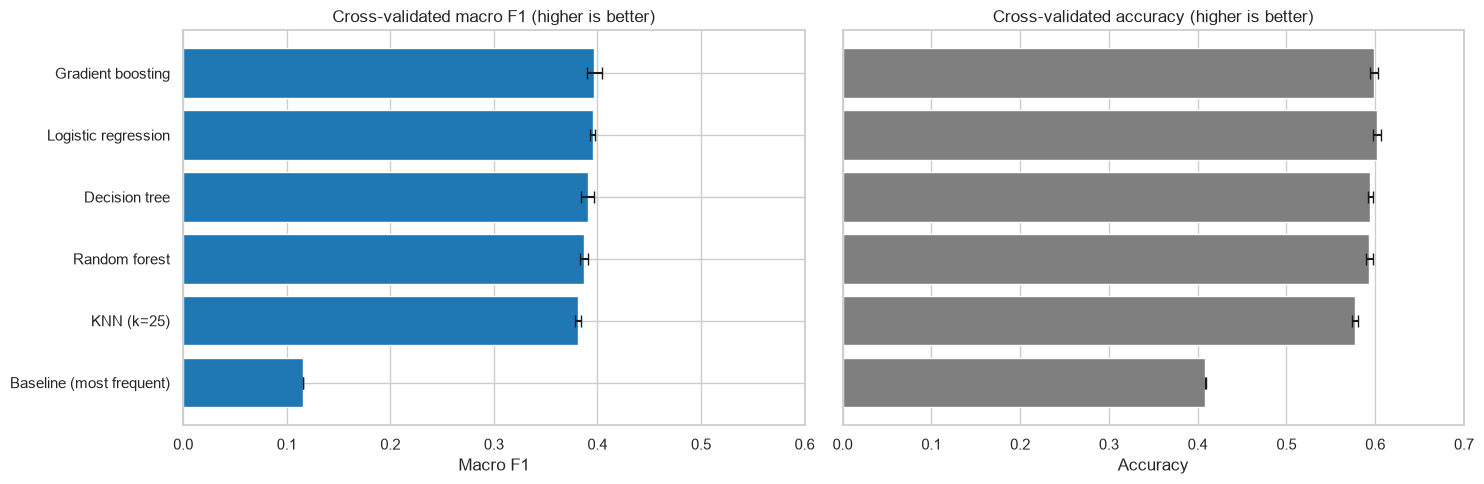

In [15]:
plot_data = classification_results.sort_values("macro F1 mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# xerr = error bars of +/- one standard deviation across the 5 folds
axes[0].barh(plot_data.index, plot_data["macro F1 mean"], xerr=plot_data["macro F1 std"], color="tab:blue", capsize=4)
axes[0].set_xlim(0, 0.6)
axes[0].set_title("Cross-validated macro F1 (higher is better)")
axes[0].set_xlabel("Macro F1")

axes[1].barh(plot_data.index, plot_data["accuracy mean"], xerr=plot_data["accuracy std"], color="tab:grey", capsize=4)
axes[1].set_xlim(0, 0.7)
axes[1].set_title("Cross-validated accuracy (higher is better)")
axes[1].set_xlabel("Accuracy")
axes[1].set_yticks([])

plt.tight_layout()
save_fig("04_04_model_comparison")
plt.show()

**Reading the results:**

* Every real model beats the baseline clearly: macro F1 rises from **0.12** to about **0.40**, and accuracy from **41%** to about **60%**.
* **Gradient boosting** (0.397) and **logistic regression** (0.395) are practically tied. The differences are smaller than the fold-to-fold variation.
* When very different models land at the same score, the limit is **the information in the data**, not the model. The next experiment shows where that information comes from.

## 3.2 Experiment: which inputs matter?

How much can we say from **fuel consumption alone**? We train the same gradient boosting model on growing sets of inputs.

gas only                           done in   1.6 s
gas + electricity                  done in   0.4 s
fuel + floor area                  done in   0.4 s
fuel + building info               done in   1.0 s
fuel + building + insulation       done in   1.1 s
Figure saved to ..\figures\04_05_feature_sets.png


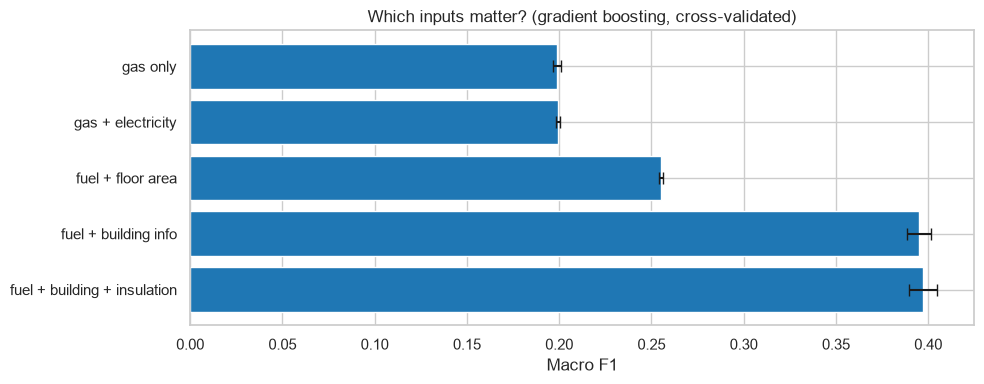

,macro F1 mean,macro F1 std,accuracy mean
model,,,
gas only,0.199,0.002,0.444
gas + electricity,0.199,0.001,0.442
fuel + floor area,0.255,0.001,0.461
fuel + building info,0.395,0.007,0.596
fuel + building + insulation,0.397,0.008,0.599


In [16]:
feature_sets = {
    "gas only": (["Gcons2024"], []),
    "gas + electricity": (fuel_features, []),
    "fuel + floor area": (fuel_features + ["FLOOR_AREA_BAND"], []),
    "fuel + building info": (fuel_features + building_numeric, building_nominal),
    "fuel + building + insulation": (numeric_features, nominal_features),
}

feature_pipelines = {
    name: make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                            numeric=num, nominal=nom, scale=False)
    for name, (num, nom) in feature_sets.items()
}

feature_results = compare_models(feature_pipelines, X_train, y_train, cv, scoring)
feature_results = feature_results.loc[list(feature_sets)]   # keep the order of the experiment

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(feature_results.index[::-1], feature_results["macro F1 mean"][::-1],
        xerr=feature_results["macro F1 std"][::-1], color="tab:blue", capsize=4)
ax.set_title("Which inputs matter? (gradient boosting, cross-validated)")
ax.set_xlabel("Macro F1")
plt.tight_layout()
save_fig("04_05_feature_sets")
plt.show()

feature_results[["macro F1 mean", "macro F1 std", "accuracy mean"]]

**Reading the results:**

* **Gas alone** gives a macro F1 of only **0.20**, and adding **electricity changes nothing** (0.199).
* Adding the **floor area** helps (**0.26**): as we saw in 1.2, gas use only means something once the size is known.
* Adding **building info** (property type, age, region) doubles the score to **0.40**. Most of the jump comes from the **property age** (see 1.3).
* The **insulation flags** add almost nothing on top (0.397).

**Conclusion:** gas and electricity consumption on their own are a **weak** predictor of the EPC band. The rating depends more on *what kind of building* it is than on *how much energy* the people living in it use.

## 3.3 Handling the imbalance: `class_weight="balanced"`

By default every home counts the same during training, so the model mostly learns the common bands (C and D). `class_weight="balanced"` gives **more weight to rare bands** (A/B, E and F/G), so the model pays more attention to them.

In [17]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, recall_score

rows = []
for weight in [None, "balanced"]:
    pipe = make_pipeline_for(HistGradientBoostingClassifier(class_weight=weight, random_state=RANDOM_STATE), scale=False)
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, n_jobs=-1)   # out-of-fold predictions
    recalls = recall_score(y_train, pred, average=None, labels=EPC_ORDER)   # recall of each band
    rows.append({
        "class_weight": str(weight),
        "accuracy": accuracy_score(y_train, pred),
        "macro F1": f1_score(y_train, pred, average="macro"),
        **{f"recall {band}": r for band, r in zip(EPC_ORDER, recalls)},
    })

pd.DataFrame(rows).set_index("class_weight")

,accuracy,macro F1,recall A/B,recall C,recall D,recall E,recall F/G
class_weight,,,,,,,
None,0.599,0.397,0.831,0.446,0.809,0.024,0.004
balanced,0.476,0.409,0.958,0.434,0.387,0.383,0.268


**Reading the results:** without weights, the model almost **never** predicts the inefficient bands: it finds only **2%** of the E homes and **0%** of the F/G homes. With `class_weight="balanced"`, it finds **38%** of E and **27%** of F/G. The price is a big drop in accuracy (**60% → 48%**), because many C and D homes are now pushed into the rare bands.

## 3.4 Tuning the best model

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31],
    "model__class_weight": [None, "balanced"],
}

start = time.time()
grid_search = GridSearchCV(
    make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
print(f"Tried {len(grid_search.cv_results_['params'])} combinations x 5 folds in {time.time() - start:.0f} s")
print("Best settings:", grid_search.best_params_)
print(f"Best cross-validated macro F1: {grid_search.best_score_:.3f} "
      f"(default settings: {classification_results.loc['Gradient boosting', 'macro F1 mean']:.3f})")

Tried 8 combinations x 5 folds in 6 s
Best settings: {'model__class_weight': 'balanced', 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 31}
Best cross-validated macro F1: 0.410 (default settings: 0.397)


In [19]:
# All tried combinations, best first
grid_table = pd.DataFrame(grid_search.cv_results_["params"]).fillna("None").astype(str)
grid_table["macro F1"] = grid_search.cv_results_["mean_test_score"]
grid_table["macro F1 std"] = grid_search.cv_results_["std_test_score"]
grid_table.sort_values("macro F1", ascending=False)

,model__class_weight,model__learning_rate,model__max_leaf_nodes,macro F1,macro F1 std
5,balanced,0.05,31,0.410,0.002
7,balanced,0.1,31,0.409,0.004
6,balanced,0.1,15,0.403,0.001
4,balanced,0.05,15,0.402,0.002
3,None,0.1,31,0.397,0.008
1,None,0.05,31,0.396,0.005
2,None,0.1,15,0.396,0.005
0,None,0.05,15,0.392,0.005


**Reading the results:** the grid search ranks the **balanced** settings first (macro F1 **0.410** vs **0.397**). We still choose the best **unweighted** model, for three reasons:

1. The gain is small: about 0.01.
2. The balanced model is much less accurate (**48%** vs **60%** of homes in exactly the right band).
3. The balanced model **over-predicts** the rarest band. On the test set, only about **4%** of its F/G predictions were correct, so it would label far too many homes as "very inefficient".

⚠️ The best score is not always the best model. Choose the model that suits **how it will be used**.

In [20]:
# Best combination WITHOUT class weights
unweighted = [(score, params) for score, params in
              zip(grid_search.cv_results_["mean_test_score"], grid_search.cv_results_["params"])
              if params["model__class_weight"] is None]
best_score, best_params = max(unweighted, key=lambda pair: pair[0])
print(f"Chosen settings: {best_params}  (cross-validated macro F1: {best_score:.3f})")

best_model = make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False)
best_model.set_params(**best_params)     # apply the chosen settings
best_model.fit(X_train, y_train);        # train on the whole training set (";" hides the long output)

Chosen settings: {'model__class_weight': None, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}  (cross-validated macro F1: 0.397)


# 4. Final evaluation on the test set
## 4.1 Classification report and confusion matrix

              precision    recall  f1-score   support

         A/B       0.68      0.81      0.74       695
           C       0.61      0.45      0.51      1906
           D       0.57      0.80      0.66      2197
           E       0.39      0.03      0.06       514
         F/G       0.00      0.00      0.00        62

    accuracy                           0.59      5374
   macro avg       0.45      0.42      0.40      5374
weighted avg       0.57      0.59      0.56      5374

Figure saved to ..\figures\04_06_confusion_matrix.png


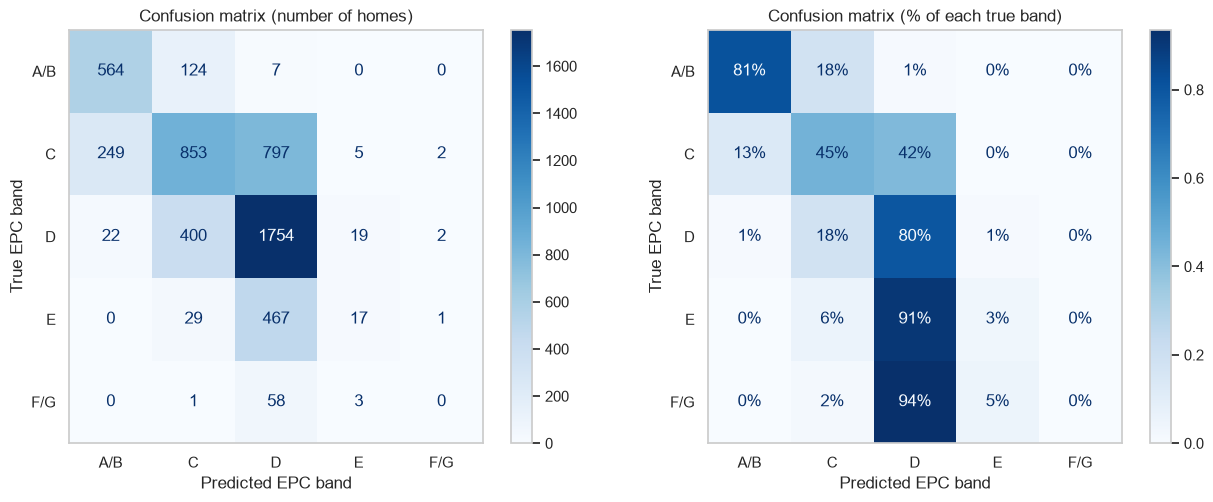

In [21]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred_test = best_model.predict(X_test)

print(classification_report(y_test, y_pred_test, labels=EPC_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=EPC_ORDER, cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (number of homes)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=EPC_ORDER, cmap="Blues", normalize="true",
                                        values_format=".0%", ax=axes[1])
axes[1].set_title("Confusion matrix (% of each true band)")
for ax in axes:
    ax.set_xlabel("Predicted EPC band")
    ax.set_ylabel("True EPC band")
    ax.grid(False)
plt.tight_layout()
save_fig("04_06_confusion_matrix")
plt.show()

**Reading the results:**

* **A/B (81%) and D (80%) are recognised well.** A/B homes are mostly new-builds, which the model spots from the age band.
* **C is often confused with D** (42%). Their consumption and building types overlap heavily.
* **E and F/G are almost always predicted as D** (91% and 94%). With so few examples, and consumption very similar to D homes, the model doesn't dare to predict them.
* Almost all mistakes are **one band off**. Mistakes of 2 or more bands are rare.

## 4.2 Predicted vs actual

Figure saved to ..\figures\04_07_test_results.png


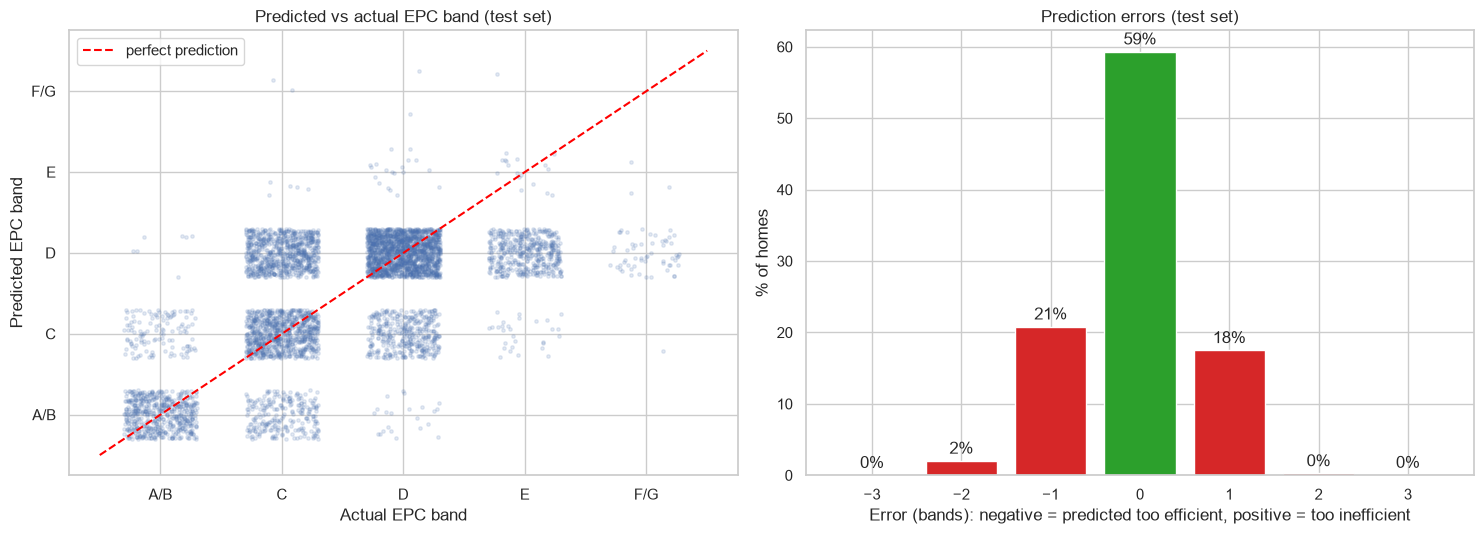

59% of the test homes are placed in exactly the right EPC band
98% of the test homes are placed within ±1 EPC band


In [22]:
true_rank = y_test.map(EPC_RANK).to_numpy()                 # A/B = 0 ... F/G = 4
pred_rank = pd.Series(y_pred_test).map(EPC_RANK).to_numpy()
band_error = pred_rank - true_rank                          # +1 = predicted one band worse, -1 = one band better
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.3, 0.3, (2, len(y_test)))   # spread the dots a little

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(true_rank + jitter[0], pred_rank + jitter[1], alpha=0.15, s=6)
axes[0].plot([-0.5, 4.5], [-0.5, 4.5], color="red", linestyle="--", label="perfect prediction")
axes[0].set_xticks(range(5), EPC_ORDER)
axes[0].set_yticks(range(5), EPC_ORDER)
axes[0].set_title("Predicted vs actual EPC band (test set)")
axes[0].set_xlabel("Actual EPC band")
axes[0].set_ylabel("Predicted EPC band")
axes[0].legend()

error_share = pd.Series(band_error).value_counts(normalize=True).sort_index() * 100
axes[1].bar(error_share.index, error_share.values,
            color=["tab:red" if e != 0 else "tab:green" for e in error_share.index])
axes[1].set_title("Prediction errors (test set)")
axes[1].set_xlabel("Error (bands): negative = predicted too efficient, positive = too inefficient")
axes[1].set_ylabel("% of homes")
for e, share in error_share.items():
    axes[1].text(e, share + 1, f"{share:.0f}%", ha="center")

plt.tight_layout()
save_fig("04_07_test_results")
plt.show()

exact = (band_error == 0).mean() * 100
within_one = (np.abs(band_error) <= 1).mean() * 100
print(f"{exact:.0f}% of the test homes are placed in exactly the right EPC band")
print(f"{within_one:.0f}% of the test homes are placed within ±1 EPC band")

💡 **Tip:** compare the test macro F1 with the cross-validated one from the grid search. If they are close, the model **generalises** well and the cross-validation was a fair estimate.

# 5. What does the model look at?

Computed in 1 s
Figure saved to ..\figures\04_08_feature_importance.png


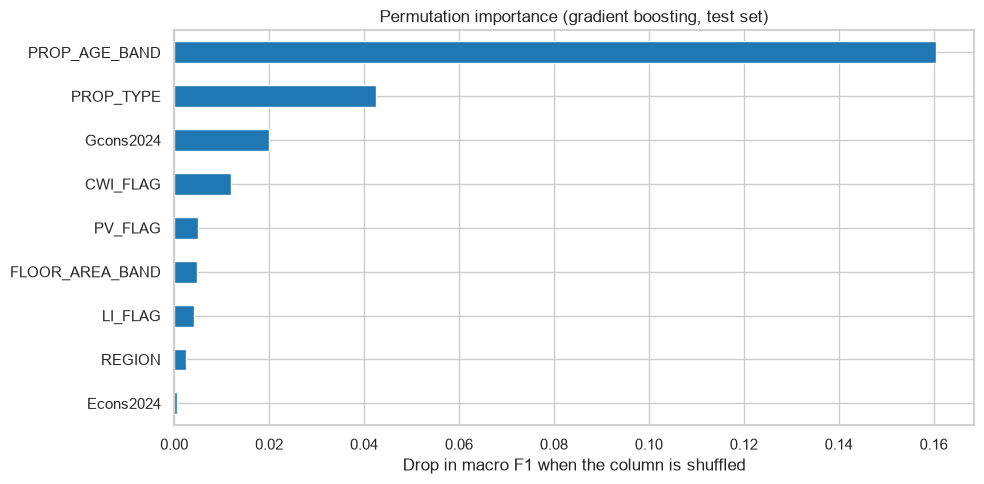

In [23]:
from sklearn.inspection import permutation_importance

start = time.time()
importance = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1_macro", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
print(f"Computed in {time.time() - start:.0f} s")

importance_series = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
importance_series.plot.barh(ax=ax, color="tab:blue")
ax.set_title("Permutation importance (gradient boosting, test set)")
ax.set_xlabel("Drop in macro F1 when the column is shuffled")
plt.tight_layout()
save_fig("04_08_feature_importance")
plt.show()

**Reading the plot:** the model relies mostly on **property age**, then **property type**, and only in third place on **gas consumption**. Cavity wall insulation adds a little. **Electricity consumption** is almost useless for this question. This confirms section 3.2: the EPC band is driven more by the building itself than by the energy actually used.

# 6. Using the model
## 6.1 Saving and loading the model

In [24]:
model_path = MODEL_DIR / "epc_band_gradient_boosting.joblib"
joblib.dump(best_model, model_path)
print(f"Model saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Later, or in another notebook / app:
loaded_model = joblib.load(model_path)

Model saved to ..\models\epc_band_gradient_boosting.joblib (0.9 MB)


## 6.2 "If this is the fuel consumption, the EPC band will be…"

In [25]:
def predict_epc(gas_kwh, elec_kwh, floor_area_band=2, prop_type="Semi detached", age_band=2,
                region="E12000008", loft_insulation=0, cavity_insulation=0, solar_pv=0):
    # Predict the EPC band of one home and print the probability of each band
    home = pd.DataFrame([{
        "Gcons2024": gas_kwh, "Econs2024": elec_kwh,
        "FLOOR_AREA_BAND": floor_area_band, "PROP_AGE_BAND": age_band,
        "LI_FLAG": loft_insulation, "CWI_FLAG": cavity_insulation, "PV_FLAG": solar_pv,
        "PROP_TYPE": prop_type, "REGION": region,
    }])
    band = loaded_model.predict(home)[0]
    probabilities = pd.Series(loaded_model.predict_proba(home)[0], index=loaded_model.classes_)[EPC_ORDER]

    print(f"{prop_type}, {FLOOR_AREA_LABELS[floor_area_band]}, age band {age_band}, {REGION_NAMES[region]}: "
          f"gas {gas_kwh:,} kWh, electricity {elec_kwh:,} kWh")
    print(f"  -> EPC band {band}")
    print("  probabilities: " + ", ".join(f"{b}: {p:.0%}" for b, p in probabilities.items()))
    return band


# The same old semi-detached house (age band 1) with low, typical and high gas use
predict_epc(gas_kwh=5_000, elec_kwh=2_500, age_band=1)
print()
predict_epc(gas_kwh=10_000, elec_kwh=2_500, age_band=1)
print()
predict_epc(gas_kwh=20_000, elec_kwh=2_500, age_band=1)
print()
# A new house (age band 4) with typical gas use
predict_epc(gas_kwh=8_000, elec_kwh=2_500, age_band=4);   # ";" hides the returned value

Semi detached, 51-100 m², age band 1, South East: gas 5,000 kWh, electricity 2,500 kWh
  -> EPC band D
  probabilities: A/B: 0%, C: 25%, D: 59%, E: 14%, F/G: 2%

Semi detached, 51-100 m², age band 1, South East: gas 10,000 kWh, electricity 2,500 kWh
  -> EPC band D
  probabilities: A/B: 0%, C: 20%, D: 57%, E: 20%, F/G: 2%

Semi detached, 51-100 m², age band 1, South East: gas 20,000 kWh, electricity 2,500 kWh
  -> EPC band D
  probabilities: A/B: 0%, C: 14%, D: 55%, E: 26%, F/G: 5%

Semi detached, 51-100 m², age band 4, South East: gas 8,000 kWh, electricity 2,500 kWh
  -> EPC band A/B
  probabilities: A/B: 58%, C: 38%, D: 3%, E: 0%, F/G: 0%


Change the numbers to try your own homes. Property types: `Flat`, `Mid terrace`, `End terrace`, `Semi detached`, `Detached`, `Bungalow`. Floor area bands: 1 (smallest) to 5 (largest). Age bands: 1 (oldest) to 4 (newest). Regions are coded (for example `E12000007` = London, see `REGION_NAMES`).

## 6.3 The model as a design tool: EPC band vs gas consumption

What does the model believe for **every** level of gas consumption? We keep one home fixed, a semi-detached house of 51–100 m² in the South East, change only its gas consumption, and plot the probability of each EPC band. We do it for an **old** home (age band 1) and a **newer** one (age band 3).

Figure saved to ..\figures\04_09_epc_vs_gas.png


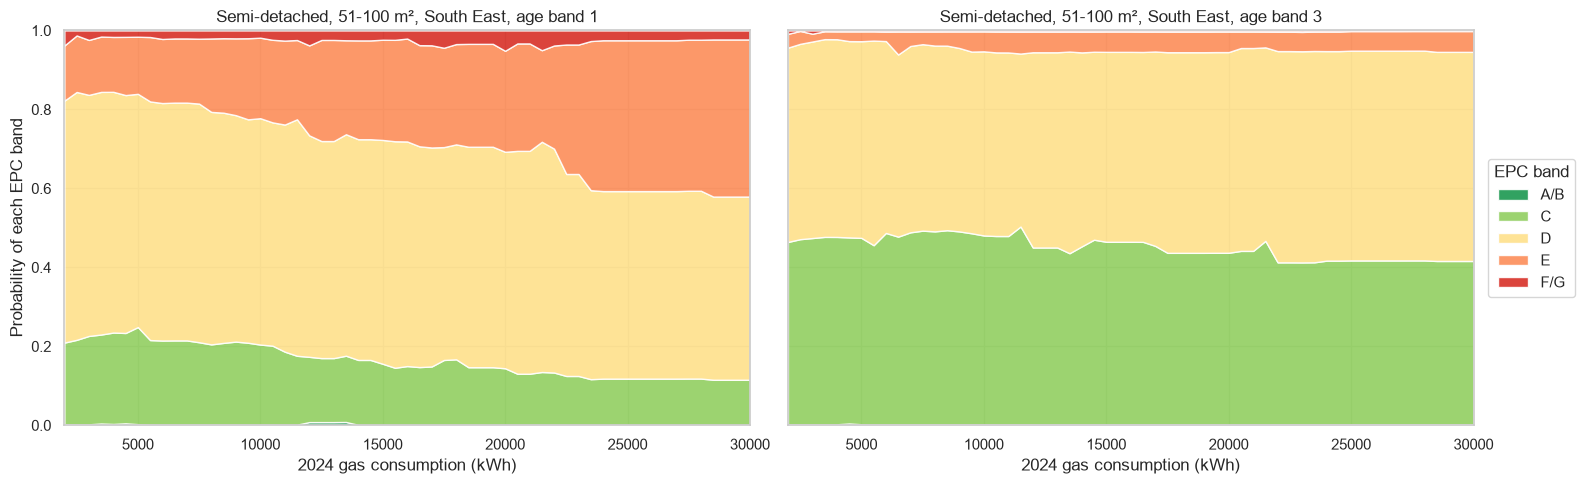

In [26]:
gas_values = np.arange(2_000, 30_001, 500)
epc_colors = ["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"]   # green (A/B) -> red (F/G)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, age_band in zip(axes, [1, 3]):
    homes = pd.DataFrame({
        "Gcons2024": gas_values, "Econs2024": 2_500, "FLOOR_AREA_BAND": 2, "PROP_AGE_BAND": age_band,
        "LI_FLAG": 0, "CWI_FLAG": 0, "PV_FLAG": 0, "PROP_TYPE": "Semi detached", "REGION": "E12000008",
    })
    probabilities = pd.DataFrame(loaded_model.predict_proba(homes), columns=loaded_model.classes_)[EPC_ORDER]
    ax.stackplot(gas_values, probabilities.T.values, labels=EPC_ORDER, colors=epc_colors, alpha=0.9)
    ax.set_title(f"Semi-detached, 51-100 m², South East, age band {age_band}")
    ax.set_xlabel("2024 gas consumption (kWh)")
    ax.set_xlim(gas_values.min(), gas_values.max())
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Probability of each EPC band")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="EPC band")
plt.tight_layout()
save_fig("04_09_epc_vs_gas")
plt.show()

**How to read it:** at each gas consumption on the x-axis, the coloured layers show how likely each EPC band is; they always add up to 100%.

* For the **old** home (age band 1), higher gas use clearly shifts the probabilities towards worse bands. The chance of **E** grows from about **15%** at 5,000 kWh to about **40%** at 25,000 kWh, while the chance of **C** shrinks. D stays the single most likely answer, though.
* For the **newer** home (age band 3), gas use hardly changes anything: the model answers C or D almost regardless of consumption.
* So gas use **does** carry information about efficiency, but it moves the probabilities rather than deciding the band.

This is how a trained model becomes a **design tool**: change one input and see how the estimate moves.

## 6.4 Estimating the rating of homes without an EPC

We set aside the homes with `No EPC` in section 2.1. The model can now give them an **estimated** rating.

In [27]:
no_epc_df["EPC_estimated"] = loaded_model.predict(no_epc_df[numeric_features + nominal_features])

comparison = pd.DataFrame({
    "homes with an EPC (%)": y.value_counts(normalize=True).reindex(EPC_ORDER) * 100,
    "homes without an EPC, estimated (%)": no_epc_df["EPC_estimated"].value_counts(normalize=True).reindex(EPC_ORDER) * 100,
}).fillna(0).round(1)
comparison

,homes with an EPC (%),"homes without an EPC, estimated (%)"
A/B,12.900,3.200
C,35.500,17.100
D,40.900,78.500
E,9.600,1.200
F/G,1.200,0.100


**Reading the results:** the model labels about **79%** of homes without an EPC as **D**, far more than the 41% of D among homes with an EPC. That's not a discovery about these homes. It shows the model's habit, seen in the confusion matrix, of choosing **D whenever it is unsure**.

⚠️ Use these estimates as a **rough indication** only, never as a replacement for a real EPC assessment.

# 7. Conclusions

* **Gas and electricity consumption alone are a weak predictor of the EPC band** (macro F1 ≈ 0.20; electricity adds nothing). The EPC rating is calculated mostly from the building fabric, not from actual energy use.
* **Gas use becomes informative once size is known.** Within the same floor area band, worse EPC bands use clearly more gas (e.g. 5,800 → 11,000 kWh in band 2).
* **Property age is the strongest predictor**, followed by property type and then gas consumption. With building information, the model reaches a macro F1 of about **0.40**. On the test set, **59%** of homes are in exactly the right band and **98%** within ±1 band.
* **The rare inefficient bands (E, F/G) are the hardest.** Without weights, the model almost never predicts them. With `class_weight="balanced"`, it finds more of them but raises many false alarms. We chose the unweighted model for its higher accuracy.
* **Compared with the floor area notebook (03):** consumption tells us much more about **how big** a home is than about **how efficient** it is.

**Next steps:**

* Use **gas consumption per m²** (energy intensity) as a feature, if exact floor areas are available.
* Use several years of consumption (`Gcons2021`–`Gcons2023`) to smooth out unusual years.
* Group the target into fewer classes (e.g. "C or better" vs "D or worse") for a simpler, more reliable model.